In [364]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.stats.diagnostic as smd
import statsmodels.stats.api as sms

In [365]:
data = pd.read_excel("data.xlsx", sheet_name = "Волгоградская")
data.columns = ["years", "x1", "x2", "x3", "x4", "x5", "x6", "x7", "y"]
data = data.set_index("years")
data.head()

,x1,x2,x3,x4,x5,x6,x7,y
years,,,,,,,,
2003,11.1,8256.20,21.40,-6.8,-13.43,99.7,47934.10,62.00
2004,9.3,11203.00,17.89,-5.8,-2.41,99.9,57928.00,65.30
2005,6.7,16136.99,17.20,-6.3,2.83,100.4,76740.60,63.70
2006,8.6,15032.40,11.90,-5.4,14.43,100.2,95683.40,65.59
2007,6.3,24729.70,13.00,-3.9,12.76,102.1,126313.09,66.09


In [366]:
X_train = data.iloc[:21, :7]
y_train = data.iloc[:21, 7:]
y_train = pd.Series(y_train.y, index = y_train.index)
X_predict = data.iloc[21:, :7]

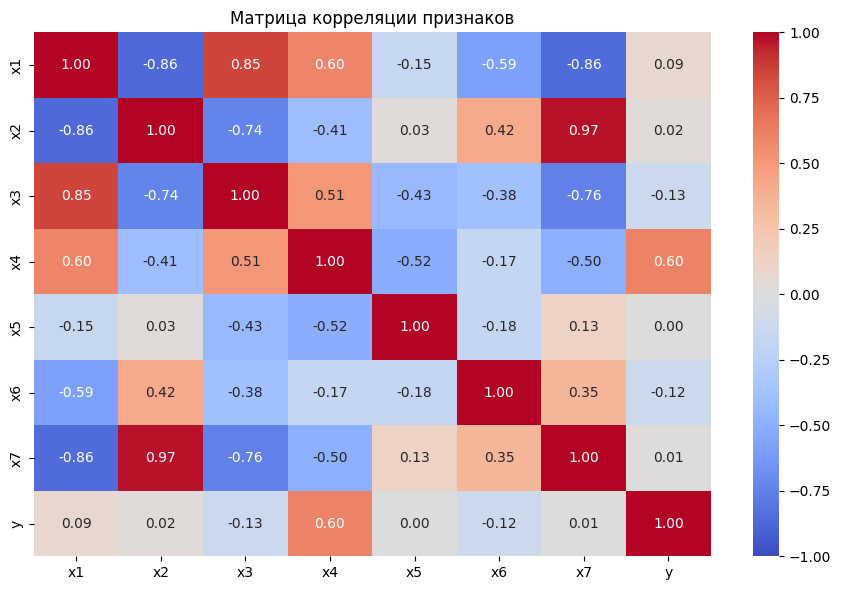

In [367]:
correlation_matrix = data.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Матрица корреляции признаков')
plt.tight_layout()
plt.show()

In [368]:
X_train = sm.add_constant(X_train)
X_predict = sm.add_constant(X_predict)

In [369]:
model = sm.OLS(y_train, X_train).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.417
Method:                 Least Squares   F-statistic:                     3.046
Date:                Fri, 23 May 2025   Prob (F-statistic):             0.0395
Time:                        12:11:55   Log-Likelihood:                -35.330
No. Observations:                  21   AIC:                             86.66
Df Residuals:                      13   BIC:                             95.02
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         81.0601     13.780      5.883      0.000      51.291     110.829
x1            -0.4138      0.469     -0.882      0.394      -1.427       0.599
x2         -8.727e-05   5.77e-05     -1.514      0.154      -0.000    3.73e-05
x3             0.3884      0.301      1.290      0.220      -0.262       1.039
x4             1.0687      0.252      4.245      0.001       0.525       1.613
x5             0.0590      0.042      1.413      0.181      -0.031       0.149
x6            -0.1449      0.114     -1.273      0.225      -0.391       0.101
x7          2.317e-05   1.33e-05      1.736      0.106   -5.67e-06     5.2e-05
==============================================================================
Omnibus:                        1.428   Durbin-Watson:                   1.597
Prob(Omnibus):                  0.490   Jarque-Bera (JB):                1.017
Skew:                          -0.252   Prob(JB):                        0.601
Kurtosis:                       2.047   Cond. No.                     1.10e+07
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.1e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [388]:
X_train_shorter = X_train.drop(columns = ["x1", "x3", "x5", "x6", "x2"])
X_predict_shorter = X_predict.drop(columns = ["x1", "x3", "x5", "x6", "x2"])

In [389]:
model_shorter = sm.OLS(y_train, X_train_shorter).fit()
model_shorter.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.313
Method:                 Least Squares   F-statistic:                     5.565
Date:                Fri, 23 May 2025   Prob (F-statistic):             0.0131
Time:                        12:15:30   Log-Likelihood:                -40.469
No. Observations:                  21   AIC:                             86.94
Df Residuals:                      18   BIC:                             90.07
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         67.5226      1.059     63.781      0.000      65.298      69.747
x4             0.5926      0.178      3.336      0.004       0.219       0.966
x7          2.251e-06   3.06e-06      0.735      0.472   -4.18e-06    8.69e-06
==============================================================================
Omnibus:                        3.771   Durbin-Watson:                   1.161
Prob(Omnibus):                  0.152   Jarque-Bera (JB):                2.359
Skew:                          -0.814   Prob(JB):                        0.307
Kurtosis:                       3.210   Cond. No.                     7.64e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.64e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

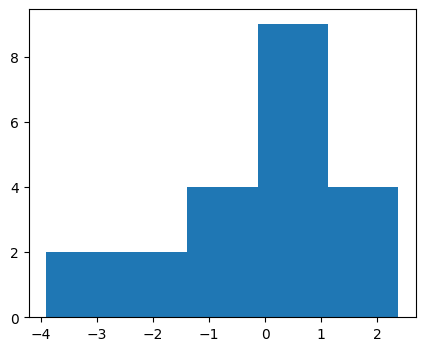

In [390]:
plt.figure(figsize = (5, 4))
plt.hist(model_shorter.resid, bins = 5)
plt.plot()
plt.show()

In [391]:
print(f"p-value: {smd.het_white(resid = model_shorter.resid, exog = X_train_shorter)[1]}")

p-value: 0.003003766332046417


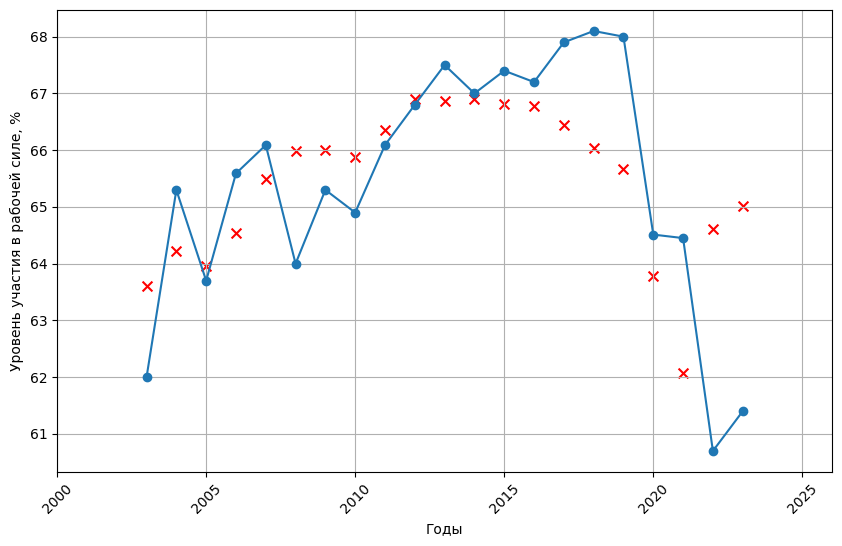

In [392]:
plt.figure(figsize=(10, 6))
plt.plot(X_train_shorter.index, y_train, label = "Фактические значения", marker = "o", linestyle = "-")
plt.scatter(X_train_shorter.index, model_shorter.fittedvalues, color = "red", label = "Предсказанные значения", marker = "x", s = 50)

plt.xlabel('Годы')
plt.xlim(2000, 2026)
plt.xticks(rotation = 45)

plt.ylabel('Уровень участия в рабочей силе, %')

plt.grid(True)
plt.show()

In [393]:
shorten_model_predictions = model_shorter.get_prediction(X_predict_shorter)
shorten_model_predictions_summary = shorten_model_predictions.summary_frame(alpha=0.05)
shorten_model_mean_predictions = pd.Series(shorten_model_predictions_summary["mean"], index = shorten_model_predictions_summary.index)
shorten_model_lower_predictions = pd.Series(shorten_model_predictions_summary["mean_ci_lower"], index = shorten_model_predictions_summary.index)
shorten_model_upper_predictions = pd.Series(shorten_model_predictions_summary["mean_ci_upper"], index = shorten_model_predictions_summary.index)

In [394]:
shorten_model_predictions_summary

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
years,,,,,,
2024,63.059855,1.069914,60.812050,65.307659,58.668881,67.450828
2025,62.490558,1.219517,59.928447,65.052669,57.930686,67.050430
2026,61.894073,1.379432,58.995994,64.792153,57.137301,66.650846


In [395]:
for _ in range(2024, 2027):

    print(f"{_}: absolute - {y_train_and_predict[_] - y_train_and_predict[2023]}, {y_train_and_predict[_]/y_train_and_predict[2023] * 100 - 100}")

2024: absolute - 1.2003220396829448, 1.9549218887344324
2025: absolute - 0.5376772707311446, 0.8756958806696247
2026: absolute - -0.14893617137791892, -0.24256705436143022


In [396]:
y_train_and_predict = y_train.combine(shorten_model_mean_predictions, max, fill_value = 0)

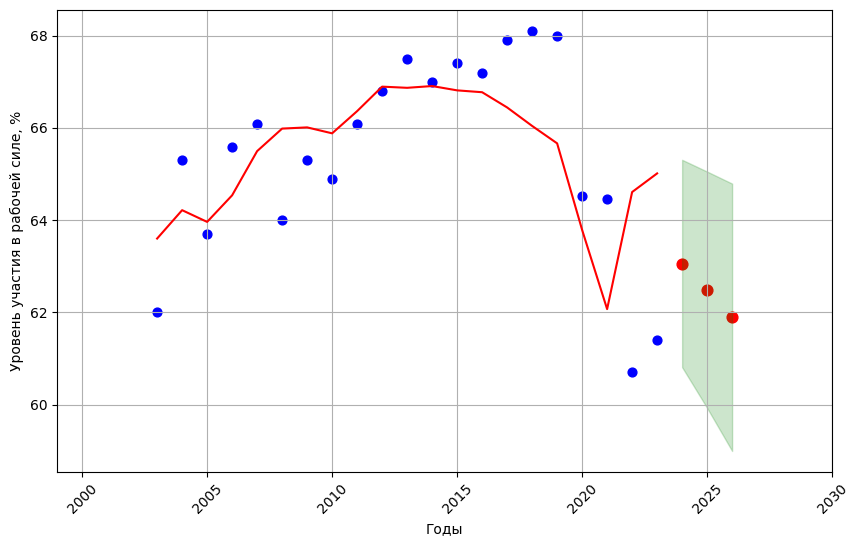

In [397]:
plt.figure(figsize=(10, 6))
plt.scatter(y_train.index, y_train, label = "Фактические значения", color = "blue", marker = "o", s = 40)
plt.plot(X_train_shorter.index, model_shorter.fittedvalues, label = "Многофакторная регрессия", linestyle = "-", color = "r")
plt.scatter(shorten_model_mean_predictions.index, shorten_model_mean_predictions, color = "red", s = 60, marker = "o", label = "Предсказанные значения")
plt.fill_between([2024, 2025, 2026], shorten_model_lower_predictions, shorten_model_upper_predictions, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.xlabel('Годы')
plt.xlim(1999, 2030)
plt.xticks(rotation = 45)

plt.ylabel('Уровень участия в рабочей силе, %')

plt.grid(True)
plt.show()